Masukkan name File Excel(sertakan ekstensi; "namafile.xlsx") : Ascidians.xlsx
Sheet/halaman yang tersedia dalam file excel kau 

['Ascidians', 'ADMET Ascidians', 'ADMET dh di kode']
Masukkan nama sheet atau lembar yang berisi data ingin digunakan : 
ADMET dh di kode
Masukkan rentang kolom awal misal kolom "C" :D
Masukkan rentang akhir dari kolom : EF
Masukkan kolom berisi data variabel ADMET : B


/tmp/ipykernel_2410/1967752525.py:36: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataFrame[kolom[0].value] = data
/tmp/ipykernel_2410/1967752525.py:36: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataFrame[kolom[0].value] = data
/tmp/ipykernel_2410/1967752525.py:36: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe =

operasi selesai


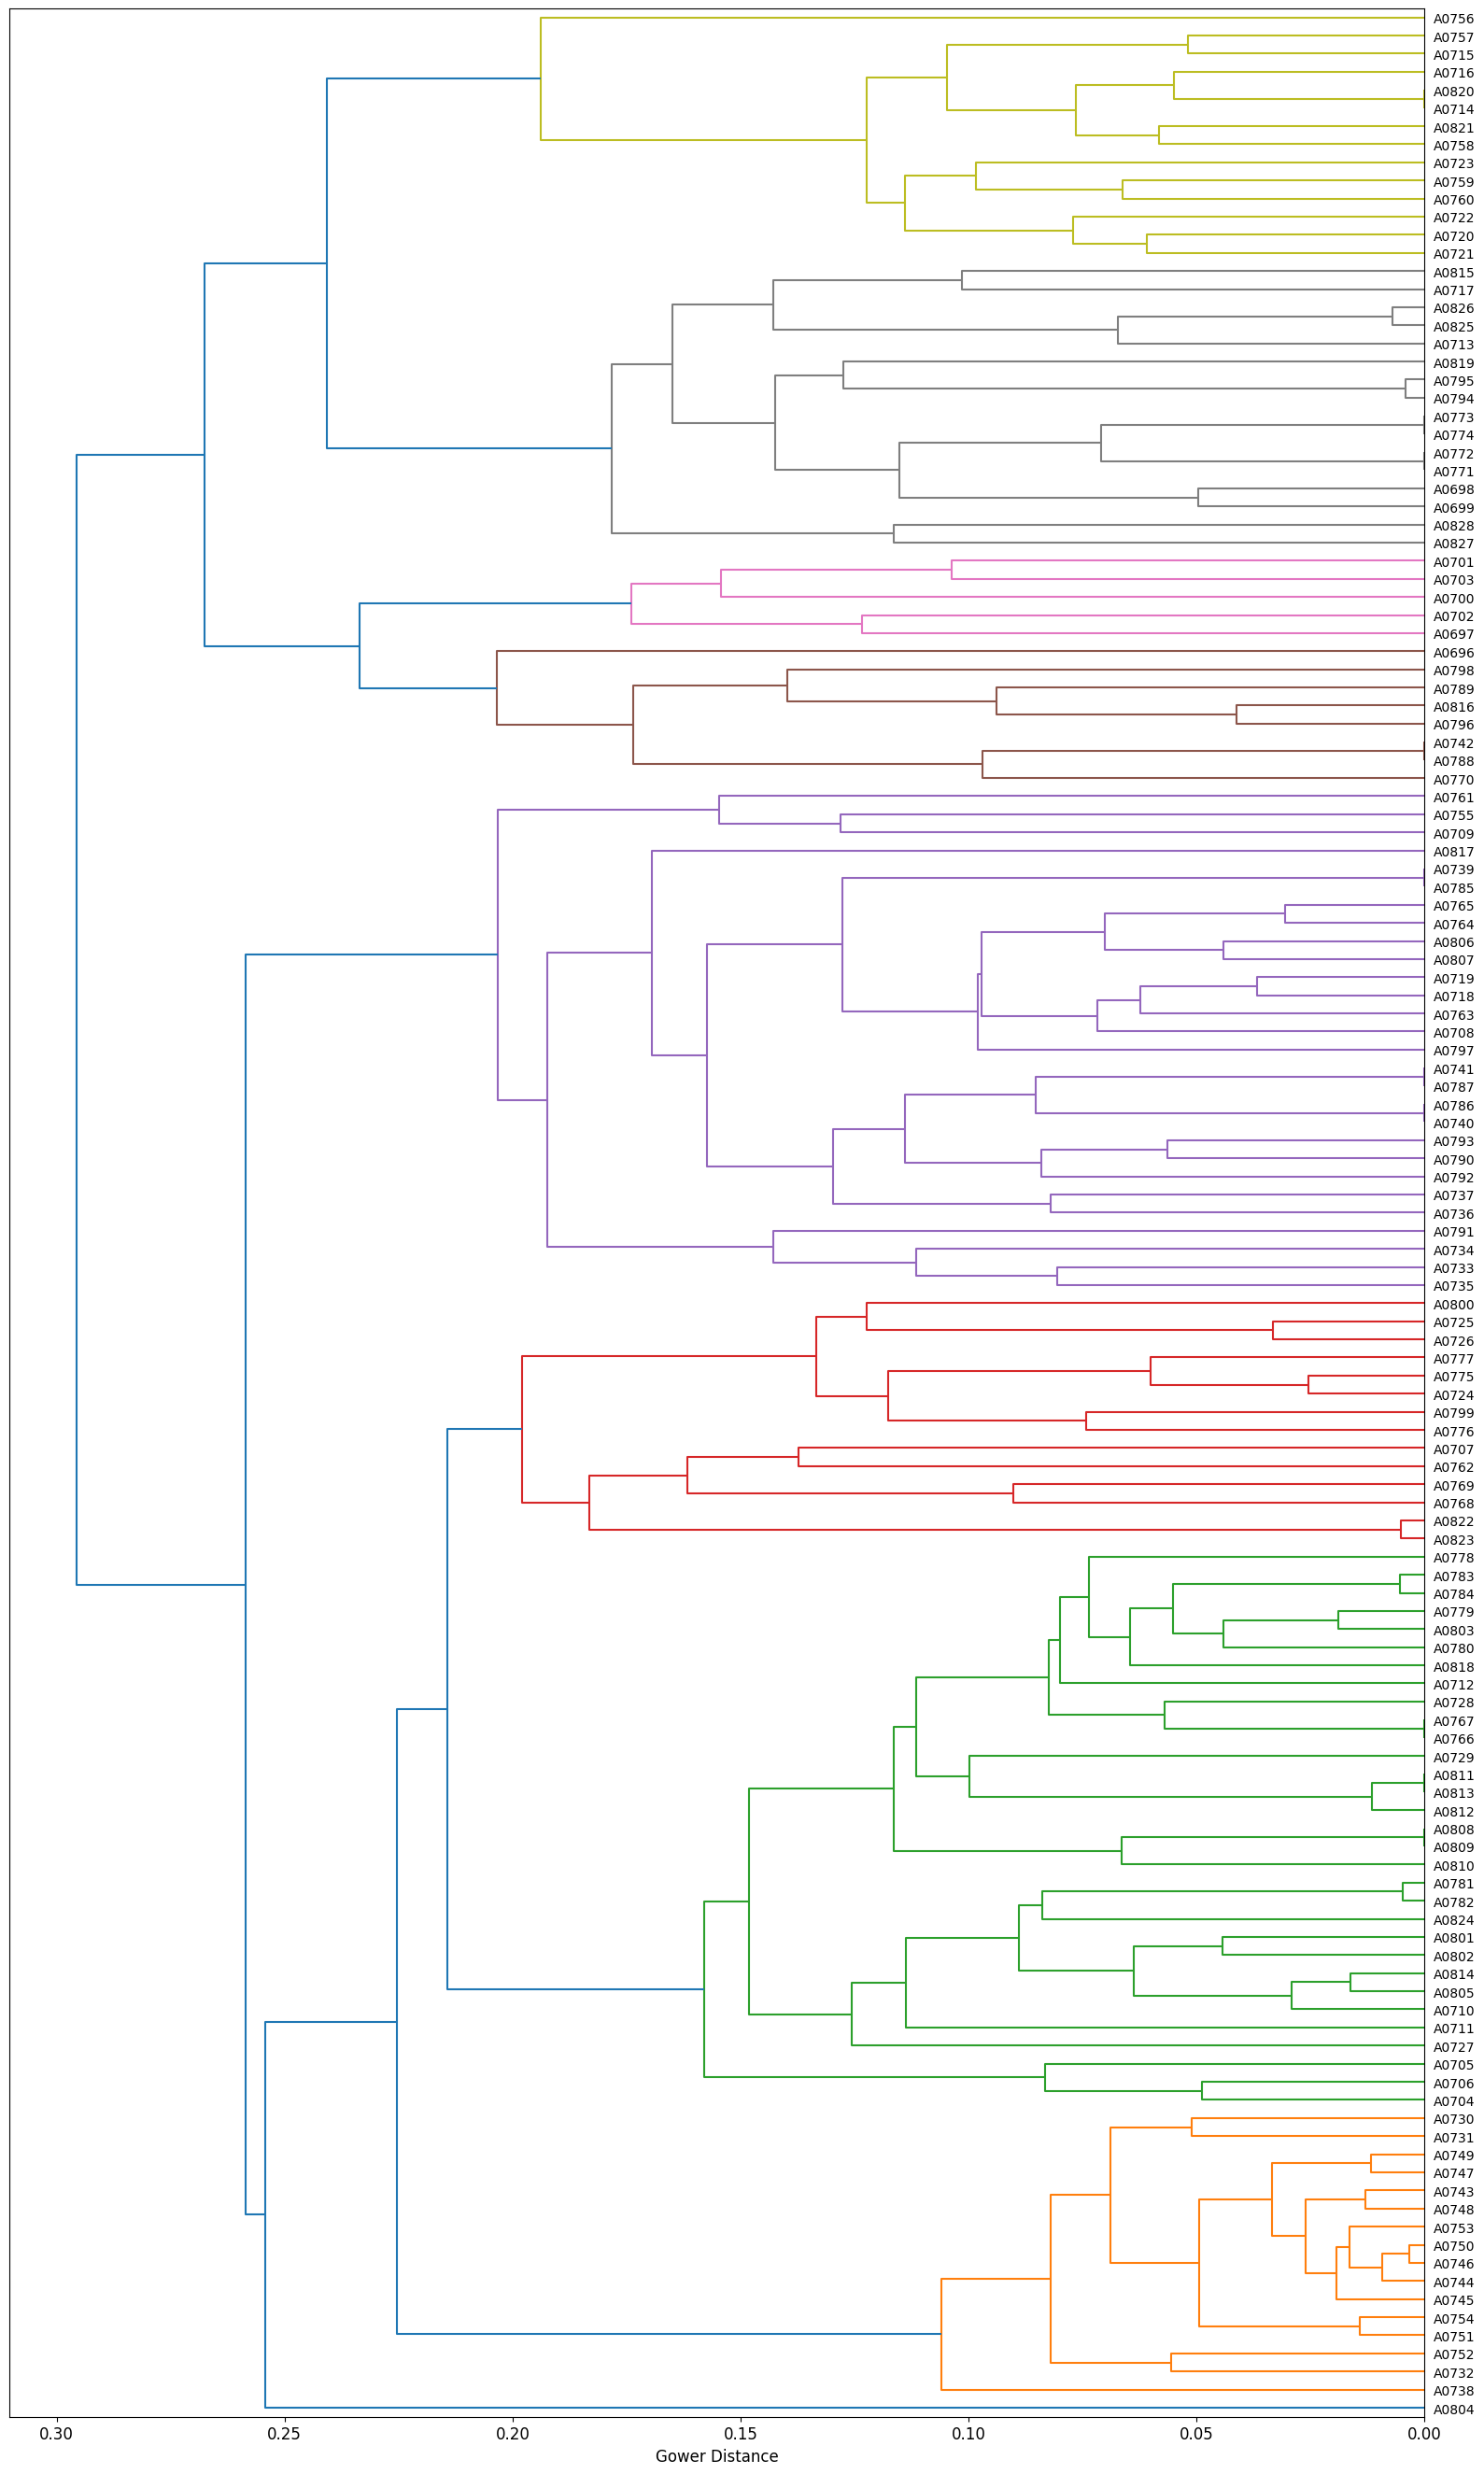

In [ ]:
# import library
from openpyxl import load_workbook
import pandas as pd
from gower import gower_matrix
import gower
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, optimal_leaf_ordering
from scipy.spatial.distance import squareform


# Input
namaFileExcel = input('Masukkan name File Excel(sertakan ekstensi; "namafile.xlsx") : ')
wb = load_workbook(namaFileExcel)
print(('Sheet/halaman yang tersedia dalam file excel kau \n ')+'=' * 50 + '\n')
print(wb.sheetnames)
sheet = wb[input('Masukkan nama sheet atau lembar yang berisi data ingin digunakan : \n')]
rentang_kolom_awal = input('Masukkan rentang kolom awal misal kolom "C" :')
rentang_kolom_akhir = input('Masukkan rentang akhir dari kolom : ')
kolom_variabel = input("Masukkan kolom berisi data variabel ADMET : ")


# DataFrame
dataFrame = pd.DataFrame()


# Iterasi pengambilan data dari File
namaVariabel = []
for variabel in sheet[kolom_variabel]:
  if variabel.value != None:
    namaVariabel.append(variabel.value)
dataFrame['Nama Variabel'] = namaVariabel

for kolom in sheet[rentang_kolom_awal:rentang_kolom_akhir]:
  data = []
  for isi in kolom[1:]:
    data.append(isi.value)
  # Tambahkan data hasil iterasi pada kolom[ke-i] ke data Frame
  dataFrame[kolom[0].value] = data

# Bagian preparasi perhitungan/Analisis data
dataAnalisis = dataFrame.set_index("Nama Variabel").T
for kolom in dataAnalisis.columns:
  hasilKonversi = pd.to_numeric(
      dataAnalisis[kolom], errors="coerce"
  )
  jumlahDataAwal = dataAnalisis[kolom].notna().sum()

  if hasilKonversi.notna().sum() == jumlahDataAwal:
    dataAnalisis[kolom] = hasilKonversi


# Bagian perhitungan
nilaiMatrix = gower.gower_matrix(dataAnalisis)
hasilHitung = pd.DataFrame(
    nilaiMatrix, index=dataAnalisis.index, columns=dataAnalisis.index
)
hasilHitung.to_csv("gower_distance.csv")

# Bagian visualisasi(diadaptasi dari file kak juli)
gower_tabel = pd.read_csv("gower_distance.csv", index_col=0) # Menggunakan index_col=0 agar nama compound menjadi index
compound_names = gower_tabel.index.astype(str).tolist()
gower_matrix = gower_tabel.to_numpy(dtype=float)

distance_data = squareform(gower_matrix, checks=False)
tree = linkage(distance_data, method="average")
tree = optimal_leaf_ordering(tree, distance_data)

nomor = len(compound_names)
fig_height = max(10, nomor* 0.2)
fig, ax = plt.subplots(figsize=(16, fig_height))

dendrogram(tree, labels=compound_names, orientation='left', leaf_font_size=9, ax=ax)
ax.set_xlabel('Gower Distance', fontsize=12)
ax.set_ylabel("")
ax.tick_params(axis='x', labelsize=12)
ax.tick_params(axis='y', labelsize=10)

fig.tight_layout()
fig.savefig("horizontal_dendogram.png", dpi=300, bbox_inches='tight')
fig.savefig("horizontal_gower_dendogram.pdf", bbox_inches='tight')

print("="*100+"\n"+"operasi selesai")
print("="*100)

In [ ]:
wb.get_sheet_names()

/tmp/ipykernel_379/1212622292.py:1: DeprecationWarning: Call to deprecated function get_sheet_names (Use wb.sheetnames).
  wb.get_sheet_names()


['Lembar1']

In [ ]:
from google.colab import files
fel = files.upload()

Saving Ascidians.xlsx to Ascidians.xlsx


In [ ]:
!pip install gower